# Convolutional Neural Network

### Importing the libraries

In [72]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import cv2
from google.colab.patches import cv2_imshow

In [73]:
tf.__version__

'2.21.0'

## Part 1 - Data Preprocessing

In [74]:
!wget https://www.dropbox.com/scl/fi/ojbrq5kyi4mncn08p5asz/cat_dog_2.zip?rlkey=jlk302r4cmu9xqn6pog9a2nj5&st=xzat507v&dl=0n

--2026-10-08 05:08:54--  https://www.dropbox.com/scl/fi/ojbrq5kyi4mncn08p5asz/cat_dog_2.zip?rlkey=jlk302r4cmu9xqn6pog9a2nj5
Resolving www.dropbox.com (www.dropbox.com)... 162.125.81.18, 2620:100:6031:18::a27d:5112
Connecting to www.dropbox.com (www.dropbox.com)|162.125.81.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://ucd78a0b18a48c2259cc3cfd1e5c.dl.dropboxusercontent.com/cd/0/inline/DJm2sM_mTGYVttmNAyyZvSZASi2rAaqNlDP8zx6epQJ_43l9vfdZ37Zk_DJyGrlN3mF2dUURDyTUTbOEJMR08ZH2iVreo-_nUMwwbsoKlnK6D9_JHADbojjdMFIT2kfA_4fyLJR914aKnzTcQDWl7N96/file# [following]
--2026-10-08 05:08:54--  https://ucd78a0b18a48c2259cc3cfd1e5c.dl.dropboxusercontent.com/cd/0/inline/DJm2sM_mTGYVttmNAyyZvSZASi2rAaqNlDP8zx6epQJ_43l9vfdZ37Zk_DJyGrlN3mF2dUURDyTUTbOEJMR08ZH2iVreo-_nUMwwbsoKlnK6D9_JHADbojjdMFIT2kfA_4fyLJR914aKnzTcQDWl7N96/file
Resolving ucd78a0b18a48c2259cc3cfd1e5c.dl.dropboxusercontent.com (ucd78a0b18a48c2259cc3cfd1e5c.dl.dropboxusercontent.com)... 162.125.80.15, 2

In [75]:
!unzip -q "/content/cat_dog_2.zip?rlkey=jlk302r4cmu9xqn6pog9a2nj5"

replace __MACOSX/._cat_dog_2? [y]es, [n]o, [A]ll, [N]one, [r]ename: None


### Preprocessing the Training set

In [76]:
training_generator = ImageDataGenerator(rescale = 1./255,
                                   shear_range = 0.2,
                                   zoom_range = 0.2,
                                   horizontal_flip = True)
train_dataset = training_generator.flow_from_directory('/content/cat_dog_2/training_set',
                                                 target_size = (64, 64),
                                                 batch_size = 32,
                                                 class_mode = 'binary')

Found 4000 images belonging to 2 classes.


In [77]:
image_view = cv2.imread('/content/cat_dog_2/training_set/cat/cat.23.jpg')

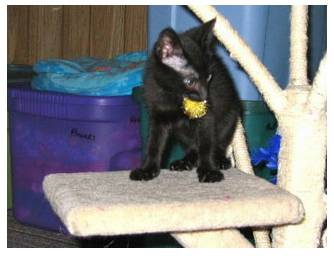

In [78]:
cv2_imshow(image_view)

In [79]:
train_dataset.classes

array([0, 0, 0, ..., 1, 1, 1], dtype=int32)

In [80]:
train_dataset.class_indices   #based on the names of the folder

{'cat': 0, 'dog': 1}

### Preprocessing the Test set

In [81]:
test_generator  = ImageDataGenerator(rescale = 1./255)
test_dataset = test_generator.flow_from_directory('/content/cat_dog_2/test_set',
                                            target_size = (64, 64),
                                            batch_size = 32,
                                            class_mode = 'binary')

Found 1000 images belonging to 2 classes.


## Part 2 - Building the CNN

### Initialising the CNN

In [82]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

In [83]:
cnn = Sequential()

### Step 1 - Convolution

In [84]:
cnn.add(Conv2D(32, (3,3), input_shape = (64,64,3), activation='relu'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


 feature detector - 32
kernal is size : 3x3

### Step 2 - Pooling

In [85]:
cnn.add(MaxPooling2D(pool_size=(2,2)))

### Adding a second convolutional layer

In [86]:
cnn.add(Conv2D(32, (3,3), activation='relu'))
cnn.add(MaxPooling2D(pool_size=(2,2)))

### Step 3 - Flattening

In [87]:
cnn.add(Flatten())

convert into 1D vector

### Step 4 - Full Connection

In [88]:
cnn.add(Dense(units = 3137, activation='relu'))
cnn.add(Dense(units = 3137, activation='relu'))


### Step 5 - Output Layer

In [89]:
cnn.add(Dense(units = 2, activation='softmax'))

In [90]:
cnn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 3137)           │    19,678,401 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3137)           │     9,843,906 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 2)              │         6,276 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,538,727 (112.68 MB)

 Trainable params: 29,538,727 (112.68 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
(6272+2)/2


3137.0

## Part 3 - Training the CNN

### Compiling the CNN

In [91]:
cnn.compile(optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])

Compiling the model is a necessary step after defining its architecture and before training the model with data.

### Training the CNN on the Training set and evaluating it on the Test set

In [ ]:
history = cnn.fit(train_dataset, epochs=10, validation_data=test_dataset)

Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 15s 103ms/step - accuracy: 0.5305 - loss: 0.8243 - val_accuracy: 0.5570 - val_loss: 0.6959
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 13s 100ms/step - accuracy: 0.6033 - loss: 0.6642 - val_accuracy: 0.6350 - val_loss: 0.6392
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 100ms/step - accuracy: 0.6580 - loss: 0.6187 - val_accuracy: 0.6680 - val_loss: 0.6018
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 98ms/step - accuracy: 0.6820 - loss: 0.6007 - val_accuracy: 0.6710 - val_loss: 0.6119
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 99ms/step - accuracy: 0.6985 - loss: 0.5763 - val_accuracy: 0.6460 - val_loss: 0.6291
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 100ms/step - accuracy: 0.7215 - loss: 0.5463 - val_accuracy: 0.7100 - val_loss: 0.5747
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 99ms/step - accuracy: 0.7280 - loss: 0.5314 - val_accuracy: 0.6850 - val_loss: 0.5857
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 98ms/step - accuracy: 0.7595 - loss: 0.498

## Part 4 - Making a single prediction

In [ ]:
import numpy as np


In [ ]:
image = cv2.imread('/content/cat_dog_2/training_set/cat/cat.1.jpg')

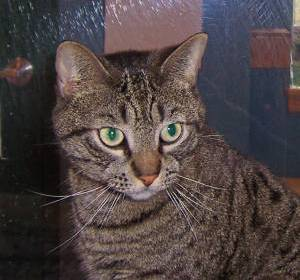

In [ ]:
cv2_imshow(image)

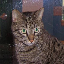

In [ ]:
image = cv2.resize(image, (64, 64))
cv2_imshow(image)

array([[[ 43,  44,  40],
        [ 49,  42,  39],
        [ 38,  37,  33],
        ...,
        [103,  80,  72],
        [126, 128, 125],
        [166, 196, 200]],

       [[ 39,  41,  36],
        [ 45,  38,  36],
        [ 46,  45,  41],
        ...,
        [114,  89,  80],
        [127, 124, 122],
        [167, 191, 199]],

       [[ 39,  40,  36],
        [ 44,  37,  34],
        [ 62,  61,  57],
        ...,
        [120, 101,  90],
        [124, 126, 123],
        [170, 198, 211]],

       ...,

       [[ 23,  23,  23],
        [ 21,  21,  21],
        [ 24,  24,  24],
        ...,
        [ 62,  65,  78],
        [ 75,  76,  91],
        [ 39,  46,  61]],

       [[ 20,  19,  21],
        [ 19,  18,  20],
        [ 22,  21,  23],
        ...,
        [ 18,  20,  38],
        [ 50,  53,  70],
        [ 45,  48,  62]],

       [[ 26,  24,  27],
        [ 23,  22,  24],
        [ 23,  22,  25],
        ...,
        [ 63,  67,  85],
        [ 59,  63,  81],
        [ 19,  26,  38]]], dtype=uint8)
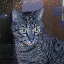

In [ ]:
image

In [ ]:
image = image / 255
image

array([[[0.16862745, 0.17254902, 0.15686275],
        [0.19215686, 0.16470588, 0.15294118],
        [0.14901961, 0.14509804, 0.12941176],
        ...,
        [0.40392157, 0.31372549, 0.28235294],
        [0.49411765, 0.50196078, 0.49019608],
        [0.65098039, 0.76862745, 0.78431373]],

       [[0.15294118, 0.16078431, 0.14117647],
        [0.17647059, 0.14901961, 0.14117647],
        [0.18039216, 0.17647059, 0.16078431],
        ...,
        [0.44705882, 0.34901961, 0.31372549],
        [0.49803922, 0.48627451, 0.47843137],
        [0.65490196, 0.74901961, 0.78039216]],

       [[0.15294118, 0.15686275, 0.14117647],
        [0.17254902, 0.14509804, 0.13333333],
        [0.24313725, 0.23921569, 0.22352941],
        ...,
        [0.47058824, 0.39607843, 0.35294118],
        [0.48627451, 0.49411765, 0.48235294],
        [0.66666667, 0.77647059, 0.82745098]],

       ...,

       [[0.09019608, 0.09019608, 0.09019608],
        [0.08235294, 0.08235294, 0.08235294],
        [0.09411765, 0

In [ ]:
image.shape

(64, 64, 3)

In [ ]:
image = image.reshape(-1, 64, 64, 3)
image.shape

(1, 64, 64, 3)

In [ ]:
result = cnn(image)
result

<tf.Tensor: shape=(1, 2), dtype=float32, numpy=array([[0.5705923, 0.4294077]], dtype=float32)>

In [ ]:
result = np.argmax(result)
result

np.int64(0)

In [ ]:
test_dataset.class_indices

{'cat': 0, 'dog': 1}

In [ ]:
if result == 0:
  print('cat')
else:
  print('dog')

cat


image.img_to_array converts the PIL image instance into a NumPy array with shape (64, 64, 3), where 3 stands for the three color channels (RGB).

np.expand_dims adds an extra dimension at the beginning of the array, transforming its shape to (1, 64, 64, 3). This is done because the CNN expects data in batches, and even though you're predicting on a single image, you need to mimic the batch dimension.

training_set.class_indices returns a dictionary mapping class names to class indices.

In [ ]:
!pip install omnivoice

from omnivoice import OmniVoice
import soundfile as sf
import torch

# Load the model
model = OmniVoice.from_pretrained(
    "k2-fsa/OmniVoice",
    device_map="cuda:0",
    dtype=torch.float16
)

# Generate audio
audio = model.generate(
    text="Hello, this is a test of zero-shot voice cloning.",
    ref_audio="ref.wav",
    ref_text="Transcription of the reference audio.",
) # audio is a list of `np.ndarray` with shape (T,) at 24 kHz.

sf.write("out.wav", audio[0], 24000)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.5/168.5 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.0/75.0 kB 8.3 MB/s eta 0:00:00


/usr/local/lib/python3.13/dist-packages/pydub/utils.py:300: SyntaxWarning: invalid escape sequence '\('
  m = re.match('([su]([0-9]{1,2})p?) \(([0-9]{1,2}) bit\)$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:301: SyntaxWarning: invalid escape sequence '\('
  m2 = re.match('([su]([0-9]{1,2})p?)( \(default\))?$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:310: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(flt)p?( \(default\))?$', token):
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:314: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(dbl)p?( \(default\))?$', token):


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]